# 07 -- Probability Calibration

## Objective

Assess the reliability of predicted probabilities from the tuned HistGradientBoosting classifier using calibration curves and the Brier score. Compare the original model with a probability-calibrated version while keeping the test set separate from model fitting and calibration.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.calibration import (
    CalibratedClassifierCV,
    CalibrationDisplay
)
from sklearn.metrics import (
    brier_score_loss,
    roc_auc_score,
    average_precision_score,
    log_loss
)

from pathlib import Path

pd.set_option("display.max_columns", None)

df = pd.read_csv(
    "../data/processed/loan_data_feature_engineered.csv"
)

print("Dataset shape:", df.shape)

Dataset shape: (44988, 14)


# Preparing the data

In [2]:
target = "Loan Status"

numeric_features = [
    "Age",
    "Employee Experience",
    "Log_Person_Income",
    "Loan Amount",
    "Credit History",
    "Credit Score",
    "Loan_to_Income"
]

categorical_features = [
    "Gender",
    "Education",
    "Home Ownership",
    "Loan Intent",
    "Previous Loan"
]

features = numeric_features + categorical_features

X = df[features].copy()
y = df[target].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (35990, 12)
Test set: (8998, 12)


# Rebuilding the tuned model

In [3]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

tuned_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            HistGradientBoostingClassifier(
                learning_rate=0.15,
                max_iter=300,
                max_leaf_nodes=15,
                min_samples_leaf=30,
                l2_regularization=0.1,
                early_stopping=False,
                random_state=42
            )
        )
    ]
)

tuned_pipeline.fit(X_train, y_train)

print("Tuned model fitted.")

Tuned model fitted.


# Obtain the original probabilities

In [4]:
y_prob_original = tuned_pipeline.predict_proba(X_test)[:, 1]

print("First 10 probabilities:")
print(np.round(y_prob_original[:10], 4))

print("\nBrier score:",
      round(brier_score_loss(y_test, y_prob_original), 4))

print("Log loss:",
      round(log_loss(y_test, y_prob_original), 4))

First 10 probabilities:
[0.2068 0.9988 0.     0.2542 0.     0.     0.1255 0.     0.3637 0.    ]

Brier score: 0.064
Log loss: 0.1946


# Plot the calibration curve

<Figure size 800x600 with 0 Axes>

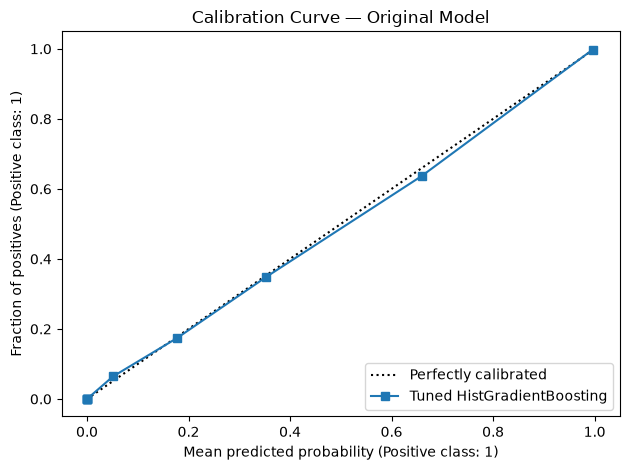

In [ ]:
plt.figure(figsize=(8, 6))

CalibrationDisplay.from_predictions(
    y_test,
    y_prob_original,
    n_bins=10,
    strategy="quantile",
    name="Tuned HistGradientBoosting"
)

plt.title("Calibration Curve -- Original Model")
plt.grid(False)
plt.tight_layout()
plt.show()

# Interpreting your calibration curve
The diagonal represents perfect calibration: if a group of observations receives predicted probabilities around 0.70, approximately 70% of those observations should belong to class 1.
Because your sigmoid-calibrated curve is closer to the diagonal, it suggests that the calibrated model's predicted probabilities align more closely with observed class frequencies across the bins. This agrees with your improved Brier score (0.0627 versus 0.0640) and log loss (0.1916 versus 0.1946).
But it is known that Calibration is not proof that every individual probability is correct, and the results may vary across groups. Still, this is a positive result for a credit-risk decisioning project.

# Calibrate using cross-validation

In [6]:
calibrated_model = CalibratedClassifierCV(
    estimator=Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            (
                "classifier",
                HistGradientBoostingClassifier(
                    learning_rate=0.15,
                    max_iter=300,
                    max_leaf_nodes=15,
                    min_samples_leaf=30,
                    l2_regularization=0.1,
                    early_stopping=False,
                    random_state=42
                )
            )
        ]
    ),
    method="sigmoid",
    cv=5,
    n_jobs=-1
)

calibrated_model.fit(X_train, y_train)

y_prob_calibrated = calibrated_model.predict_proba(X_test)[:, 1]

print("Calibrated model fitted.")

Calibrated model fitted.


# Compare probability quality

In [7]:
calibration_results = pd.DataFrame([
    {
        "Model": "Original Tuned Model",
        "Brier Score": brier_score_loss(
            y_test, y_prob_original
        ),
        "Log Loss": log_loss(
            y_test, y_prob_original
        ),
        "ROC-AUC": roc_auc_score(
            y_test, y_prob_original
        ),
        "Average Precision": average_precision_score(
            y_test, y_prob_original
        )
    },
    {
        "Model": "Sigmoid-Calibrated Model",
        "Brier Score": brier_score_loss(
            y_test, y_prob_calibrated
        ),
        "Log Loss": log_loss(
            y_test, y_prob_calibrated
        ),
        "ROC-AUC": roc_auc_score(
            y_test, y_prob_calibrated
        ),
        "Average Precision": average_precision_score(
            y_test, y_prob_calibrated
        )
    }
])

display(calibration_results.round(4))

,Model,Brier Score,Log Loss,ROC-AUC,Average Precision
0,Original Tuned Model,0.0640,0.1946,0.9609,0.8932
1,Sigmoid-Calibrated Model,0.0627,0.1916,0.9626,0.8975


# Save the results and calibrated model

In [8]:
import joblib

reports_dir = Path("../reports")
models_dir = Path("../models")

reports_dir.mkdir(parents=True, exist_ok=True)
models_dir.mkdir(parents=True, exist_ok=True)

calibration_results.to_csv(
    reports_dir / "probability_calibration_results.csv",
    index=False
)

joblib.dump(
    calibrated_model,
    models_dir / "hist_gradient_boosting_calibrated.joblib"
)

print("Calibration results and model saved.")

Calibration results and model saved.


### Probability Calibration Results

The tuned HistGradientBoosting classifier was evaluated before and after sigmoid probability calibration. The original model achieved a Brier score of 0.0640, log loss of 0.1946, ROC-AUC of 0.9609, and average precision of 0.8932. Following calibration, these values improved to 0.0627, 0.1916, 0.9626, and 0.8975, respectively.

The lower Brier score and log loss suggest improved probability quality, while the increases in ROC-AUC and average precision indicate a modest improvement in discrimination and precision-recall performance. Based on these results, the sigmoid-calibrated model is retained as the preferred candidate for subsequent evaluation.

However, these metrics alone do not establish that the probabilities are well calibrated. The calibration curves should also be examined, and the reported improvements should be interpreted as descriptive comparisons rather than statistically significant differences. Further evaluation is required before using the probabilities to make operational loan decisions.